In [1]:
!pip install yfinance scikit-learn

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   --------- ---------------------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

In [3]:
df = yf.download('RELIANCE.NS', period='2y')
df = df[['Open','High','Low','Close','Volume']]
df = df.dropna()
print(df.head())

[*********************100%***********************]  1 of 1 completed

Price              Open         High          Low        Close      Volume
Ticker      RELIANCE.NS  RELIANCE.NS  RELIANCE.NS  RELIANCE.NS RELIANCE.NS
Date                                                                      
2024-11-05  1281.929288  1298.337635  1275.137962  1294.124023    16267479
2024-11-06  1298.783650  1316.927012  1289.067510  1314.002197    21625209
2024-11-07  1312.663809  1312.663809  1291.447013  1294.470947     9611974
2024-11-08  1286.539557  1290.505310  1264.083462  1272.758545    19814406
2024-11-11  1267.999465  1274.989151  1256.151831  1261.802979     9056552


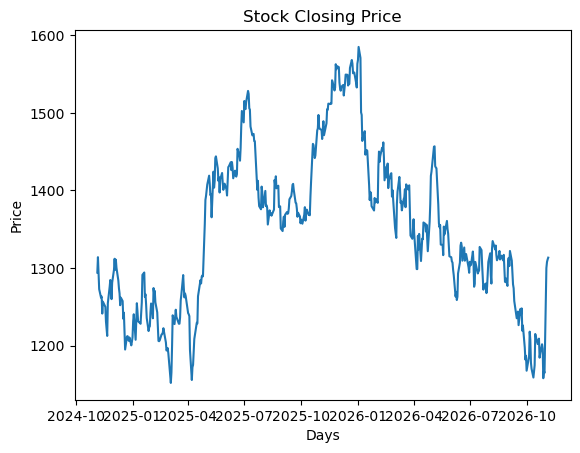

In [4]:
plt.plot(df['Close'])
plt.title('Stock Closing Price')
plt.xlabel('Days')
plt.ylabel('Price')
plt.show()

In [5]:
scaler = MinMaxScaler()
scaled = scaler.fit_transform(df)

In [6]:
X,y = [],[]
for i in range(30,len(scaled)):
    X.append(scaled[i-30:i])
    y.append(scaled[i,3])

X,y = np.array(X),np.array(y)

In [7]:
split = int(0.8*len(X))
X_train,X_test = X[:split],X[split:]
y_train,y_test = y[:split],y[split:]

X_train,X_val = X_train[:int(.8*len(X_train))],X_train[int(.8*len(X_train)):]
y_train,y_val = y_train[:int(.8*len(y_train))],y_train[int(.8*len(y_train)):]

In [8]:
model = Sequential([
    SimpleRNN(50,input_shape=(30,5)),
    Dense(1)
])
model.compile(optimizer='adam',loss='mse')
model.summary()

C:\Users\Lenovo\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 50)                  │           2,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,851 (11.14 KB)

 Trainable params: 2,851 (11.14 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(X_train,y_train,epochs=3,batch_size=32,validation_data=(X_val,y_val))

Epoch 1/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 94ms/step - loss: 0.1579 - val_loss: 0.1047
Epoch 2/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0405 - val_loss: 0.0128
Epoch 3/3
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0196 - val_loss: 0.0142


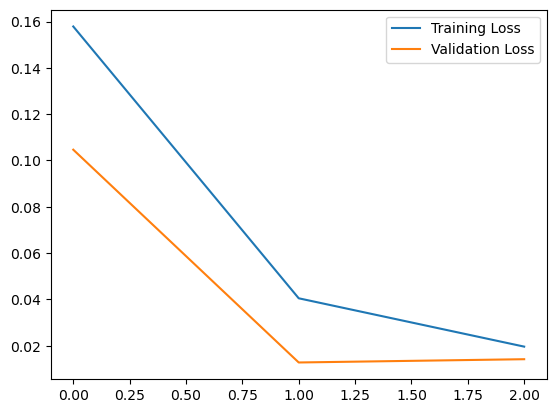

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0139
Test Loss: 0.013891767710447311


In [10]:
plt.plot(history.history['loss'],label='Training Loss')
plt.plot(history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.show()

print("Test Loss:",model.evaluate(X_test,y_test))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step


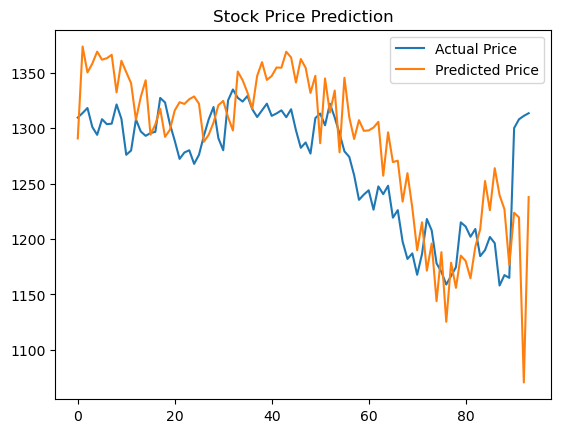

In [11]:
pred = model.predict(X_test)
pred = (pred-scaler.min_[3])/scaler.scale_[3]
actual = (y_test-scaler.min_[3])/scaler.scale_[3]

plt.plot(actual,label='Actual Price')
plt.plot(pred,label='Predicted Price')
plt.legend()
plt.title('Stock Price Prediction')
plt.show()